# Respiratory forecasting: calculation review

This notebook traces the paper's saved forecasts to its reported scores and geographic maps.
It is a **retrospective arithmetic review**, not a new training experiment. Experiments 1–3
independently retrain the same framework on NSSP, contemporary ILINet and historical ILINet;
they do not transfer one fitted model between surveillance systems.

**Main NSSP result:** one contribution per **Health Service Area (HSA) per week** gives R² = **0.599**, RMSE = **0.972
percentage points**, and N = **13,356**. The original record-weighted result, R² = **0.671**,
RMSE = **0.803**, N = **47,534**, is a comparison. This post-review reporting amendment uses
unchanged forecasts; training and validation retain their original record weighting.
All three final-test windows were inspected during development, so these are exploratory,
not untouched confirmatory, comparisons.

## Start and scope

- Saved tables and maps can be read without running cells. To recalculate them, use Python 3.12,
  install `requirements-review.txt`, and place the matching `reference_calculations.zip` in `data/`.
  Follow the [data-access instructions](../data/README.md); the public download URL is still pending.
- Start Jupyter in this repository and run cells in order. Leave **all four Section 7 switches off**.
  Default execution reads evidence, checks arithmetic and displays existing images; it does not fit
  models, extract files, export results or redraw maps.
- `EXPERIMENT_INDEX` and `ROW_INDEX` select worked examples in Sections 1–3. Section 4 checks all
  experiments; its side-by-side table and Section 5's Alabama/Texas examples remain NSSP-specific.
  Sections 5 and 6 include all three experiments regardless of that selector.
- Full implementations are linked beside each calculation and indexed in the
  [function index](../docs/FUNCTION_INDEX.md). The [calculation guide](../docs/CALCULATIONS.md)
  and [companion evidence guide](../supplement/README.md) provide further detail.

The notebook does not recreate scikit-learn or statsmodels internally. Fitted estimator objects
were not archived, so prediction CSVs cannot reveal individual tree paths or MLP activations.
Exact raw snapshots are needed to verify original feature inputs or refit the models.

In [1]:
from pathlib import Path
import csv, hashlib, io, json, math, statistics, sys, zipfile
from collections import defaultdict
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/REFERENCE_ARCHIVE.json").exists())
ARCHIVE = ROOT / "data/reference_calculations.zip"
assert ARCHIVE.exists(), "Place the matching reference_calculations.zip in data/ (see data/README.md)."
manifest = json.loads((ROOT / "data/REFERENCE_ARCHIVE.json").read_text())
with ARCHIVE.open("rb") as stream:
    assert hashlib.file_digest(stream, "sha256").hexdigest() == manifest["sha256"]
ARCHIVE_HASHES = {row["path"]: row["sha256"] for row in manifest["files"]}

# Input helper only: unzip/read bytes, check recorded SHA-256, parse CSV strings.
# It performs no forecasting or mathematical transformations.
def rows(relative):
    if relative in ARCHIVE_HASHES:
        with zipfile.ZipFile(ARCHIVE) as z:
            raw = z.read(relative)
        assert hashlib.sha256(raw).hexdigest() == ARCHIVE_HASHES[relative], relative
        text = raw.decode("utf-8-sig")
    else:
        text = (ROOT / relative).read_text(encoding="utf-8-sig")
    return list(csv.DictReader(io.StringIO(text)))

EXPERIMENTS = [
    ("experiment_1_nssp_primary", "percent_visits_combined", ["geography", "county", "epi_order"],
     "nssp_full/test/AR1/predictions.csv", "nssp_full/test/SARIMA_100x100_52/predictions.csv"),
    ("experiment_2_ilinet_contemporary", "%UNWEIGHTED ILI", ["REGION TYPE", "REGION", "epi_order"],
     "arima_extension_exp2_exp3/exp2/final_test_predictions.csv", "exp2/final_test_predictions.csv"),
    ("experiment_3_ilinet_pandemic_stress_test", "%UNWEIGHTED ILI", ["REGION TYPE", "REGION", "epi_order"],
     "arima_extension_exp2_exp3/exp3/final_test_predictions.csv", "exp3/final_test_predictions.csv"),
]
EXPERIMENT_INDEX = 0  # Change to 1 or 2 to inspect the other experiment; no model refit.
ROW_INDEX = 0        # Change to inspect another saved forecast.
name, target, keys, _, _ = EXPERIMENTS[EXPERIMENT_INDEX]
prefix = f"results/reference/hybrid/{name}"
prediction_rows = rows(f"{prefix}/predictions/{name}_predictions.csv")
row = prediction_rows[ROW_INDEX]
print("Evidence archive verified. Python", sys.version.split()[0])
print("Selected forecast key:", {k: row[k] for k in keys})


# Display formatting only: no scoring, model calls, or file writes.
def show_table(title, headers, body):
    def shown(value):
        if isinstance(value, float):
            return f"{value:,.6f}"
        if isinstance(value, int):
            return f"{value:,}"
        return str(value).replace("|", r"\|").replace("\n", " ")
    lines = [f"### {title}", "", "| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    lines.extend("| " + " | ".join(shown(value) for value in record) + " |" for record in body)
    display(Markdown("\n".join(lines)))

Evidence archive verified. Python 3.12.10
Selected forecast key: {'geography': 'Alabama', 'county': 'All', 'epi_order': '202419'}


## 1. Forecast inputs

The selected row contains target lags 1–3, their three-observation mean and sample standard
deviation (denominator 2), and annual terms `sin(2π × week / 52)` and `cos(2π × week / 52)`.
NSSP also uses lag-1 COVID-19, influenza and RSV percentages; ILINet uses lag-1 provider count.
Current-week auxiliary shares, smoothed inputs and trend measures are excluded.

`shift(k)` takes the preceding **k observations within the sorted reporting series**, not an
explicit calendar-week join. Week 53 has the same encoded phase as Week 1. The retrospective
framework assumes completed-week observations are immediately available; it does not reconstruct
reporting delays or later revisions.

The next cell checks the arithmetic of stored features. It does not independently verify the
earlier raw observations. Implementation:
[`add_time_series_features` and `choose_feature_columns`](../src/common_features.py).

In [2]:
previous = [float(row[f"lag_{k}"]) for k in (1, 2, 3)]
rolling_mean = sum(previous) / 3
rolling_std = math.sqrt(sum((value - rolling_mean)**2 for value in previous) / 2)
week = float(row["WEEK"])
calculated_features = {"rolling_mean_3": rolling_mean, "rolling_std_3": rolling_std,
                       "week_sin": math.sin(2*math.pi*week/52),
                       "week_cos": math.cos(2*math.pi*week/52)}
print("Previous target observations:", previous)
for feature, calculated in calculated_features.items():
    saved = float(row[feature])
    assert math.isclose(calculated, saved, rel_tol=1e-9, abs_tol=1e-9)
    print(feature, "calculated =", calculated, "saved =", saved)
print("Auxiliary lag fields:", {k:v for k,v in row.items() if k.endswith("_lag_1")})

Previous target observations: [0.8, 0.73, 0.91]
rolling_mean_3 calculated = 0.8133333333333334 saved = 0.8133333333333334
rolling_std_3 calculated = 0.09073771725877469 saved = 0.09073771725934414
week_sin calculated = 0.7485107481711013 saved = 0.7485107481711013
week_cos calculated = -0.663122658240795 saved = -0.663122658240795
Auxiliary lag fields: {'percent_visits_covid_lag_1': '0.35', 'percent_visits_influenza_lag_1': '0.4', 'percent_visits_rsv_lag_1': '0.06'}


## 2. Fitting boundaries and model configuration

The earlier pre-test segment fits the scaler, K-means and learners; the latest 20% of pre-test
weeks estimates ensemble weights. All objects are then refitted on complete pre-test history,
with those weights fixed. Final-test observations update later forecast inputs, not fitted
parameters. Each experiment estimates its own objects.

Standardization uses fitting-row means and **population** standard deviations, unlike the sample
rolling SD in Section 1. K-means minimizes within-cluster squared distance and appends one-hot
indicators. K = 4 is retained across experiments with newly fitted centroids. The MLP's internal
15% early-stopping subset is random within its supplied fitting rows, not the chronological
ensemble-validation split.

| Calculation | Implementation and package |
|---|---|
| Chronological validation split; scaling; clustering | [`common_features.py`](../src/common_features.py): `chronological_validation_split`, `fit_preprocessor`, `transform_preprocessor`; scikit-learn `StandardScaler` and `KMeans` |
| RF, GBR and MLP settings | [`common_config.py`](../src/common_config.py) and [`build_models`](../src/common_models.py); scikit-learn regressors |
| Weight estimation and full-history refit | [`common_models.py`](../src/common_models.py): `compute_validation_weights`, `fit_predict_final_models` |

The table below describes the **selected experiment's original fitting cohort**, not NSSP's
later HSA-week scoring units. Full settings, cluster-selection evidence and profiles are in the
[companion evidence](../supplement/README.md). A clean full-training reproduction is not established
by these saved-calculation checks. In particular, archived classical runs record pandas 3.0.1,
whereas the preserved dependency file pins 3.0.3.

In [3]:
# Read saved metadata only; the linked fitting functions are not imported or called.
metadata_path = f"{prefix}/metrics/{name}_run_metadata.csv"
metadata_rows = rows(metadata_path)
assert len(metadata_rows) == 1
selected_metadata = metadata_rows[0]
metadata_fields = ["Experiment", "Dataset_Type", "Split_Description", "Test_Cutoff",
                   "Validation_Cutoff", "Fit_Rows", "Validation_Rows", "Train_Rows",
                   "Test_Rows", "Feature_Count", "Requested_N_Clusters",
                   "Validation_Effective_N_Clusters", "Final_Effective_N_Clusters"]
show_table("Saved fitting and cohort metadata", ["Field", "Value"],
           [[field, selected_metadata[field]] for field in metadata_fields])
display(Markdown(f"Full metadata: [{metadata_path}](../{metadata_path})."))

### Saved fitting and cohort metadata

| Field | Value |
| --- | --- |
| Experiment | experiment_1_nssp_primary |
| Dataset_Type | nssp |
| Split_Description | test begins at epi_order 202419 |
| Test_Cutoff | 202419 |
| Validation_Cutoff | 202402 |
| Fit_Rows | 144896 |
| Validation_Rows | 38488 |
| Train_Rows | 183384 |
| Test_Rows | 47534 |
| Feature_Count | 14 |
| Requested_N_Clusters | 4 |
| Validation_Effective_N_Clusters | 4 |
| Final_Effective_N_Clusters | 4 |

Full metadata: [results/reference/hybrid/experiment_1_nssp_primary/metrics/experiment_1_nssp_primary_run_metadata.csv](../results/reference/hybrid/experiment_1_nssp_primary/metrics/experiment_1_nssp_primary_run_metadata.csv).

## 3. Reconstruct one ensemble forecast

For saved validation MSE $E_j$, calculate inverse-error coefficients and normalize them:

$$
a_j=1/\max(E_j,10^{-12}),\qquad w_j=a_j/\sum_k a_k
$$

The floor prevents division by zero. The final forecast is the weighted sum of the three
saved component predictions:

$$
\hat{y}=\sum_j w_j\hat{y}_j
$$

The following table reconstructs the selected forecast and checks it against the saved hybrid.
Validation per-row component predictions were not archived by the primary runner: their MSE
calculation is traceable in [`compute_validation_weights`](../src/common_models.py), but cannot
be independently repeated here without refitting. Test component forecasts **are** archived.
The final refit does not re-estimate weights.

In [4]:
# Source: src/common_models.py::inverse_mse_weights and ::compute_validation_weights.
# This independent reconstruction uses saved validation MSE and test predictions.
weight_rows = rows(f"{prefix}/metrics/{name}_ensemble_weights.csv")
inverse = {r["Model"]: 1 / max(float(r["Validation_MSE"]), 1e-12) for r in weight_rows}
weights = {model: value / sum(inverse.values()) for model, value in inverse.items()}
contributions = []
contribution_table = []
for saved in weight_rows:
    model = saved["Model"]
    assert math.isclose(weights[model], float(saved["Weight"]), rel_tol=1e-12, abs_tol=1e-12)
    prediction = float(row[model])
    contribution = weights[model] * prediction
    contributions.append(contribution)
    contribution_table.append([model, float(saved["Validation_MSE"]), weights[model], prediction, contribution])
reconstructed = sum(contributions)
assert math.isclose(reconstructed, float(row["Hybrid_InvMSE"]), rel_tol=1e-12, abs_tol=1e-12)
show_table("Selected forecast: component contributions",
           ["Model", "Validation MSE", "Weight", "Prediction (%)", "Weighted contribution"], contribution_table)
example_error = reconstructed - float(row[target])
show_table("Selected forecast: sum and error",
           ["Observed (%)", "Reconstructed hybrid (%)", "Saved hybrid (%)", "Error (pp)", "Squared error (pp²)"],
           [[float(row[target]), reconstructed, float(row["Hybrid_InvMSE"]), example_error, example_error**2]])
print("PASS: weights and selected hybrid forecast match the archived values.")

### Selected forecast: component contributions

| Model | Validation MSE | Weight | Prediction (%) | Weighted contribution |
| --- | --- | --- | --- | --- |
| RandomForest | 5.247683 | 0.309662 | 0.620467 | 0.192135 |
| GradientBoosting | 3.570295 | 0.455147 | 0.676159 | 0.307752 |
| MLP | 6.909318 | 0.235191 | 0.779021 | 0.183219 |

### Selected forecast: sum and error

| Observed (%) | Reconstructed hybrid (%) | Saved hybrid (%) | Error (pp) | Squared error (pp²) |
| --- | --- | --- | --- | --- |
| 0.580000 | 0.683105 | 0.683105 | 0.103105 | 0.010631 |

PASS: weights and selected hybrid forecast match the archived values.


## 4. Primary HSA-week scores and record-weighted comparison

For each scored pair, the error is $e_i=\hat{y}_i-y_i$. The arithmetic is:

$$
\bar{y}=\frac{1}{N}\sum_{i=1}^{N}y_i
$$

$$
\mathrm{SSE}=\sum_{i=1}^{N}e_i^2
$$

$$
\mathrm{SST}=\sum_{i=1}^{N}(y_i-\bar{y})^2
$$

$$
R^2=1-\frac{\mathrm{SSE}}{\mathrm{SST}}
$$

$$
\mathrm{RMSE}=\sqrt{\frac{\mathrm{SSE}}{N}}
$$

SSE sums squared errors; SST measures observed variation around the **scoring cohort's own mean**.
R² compares with that mean-based reference, not persistence, and is not a percentage of correct
forecasts. RMSE is in percentage points; SSE/SST use squared percentage points. Their unnormalized
totals are not directly comparable across differently sized cohorts.

### Scoring units

Of 47,534 original NSSP test records, 46,515 have `trend_source == "HSA"`; the 998 state and
21 national records are excluded from primary scoring. Averaging target and each model prediction
within `hsa_nci_id`/`epi_order` gives **636 HSAs × 21 weeks = 13,356 HSA-weeks**. The following
cells read the [saved aggregation](../manuscript/latex/sensitivity_data/S3_hsa_week_mean_predictions.csv)
and verify its scores, not regroup the raw surveillance data. The grouping implementation is
[`sensitivity_analysis.py::main`](../manuscript/latex/sensitivity_analysis.py).

For the hybrid, repeated county-key rows within an HSA-week have the same target and forecast
within numerical tolerance. Counting each HSA-week once changes geographic scoring influence,
not these forecasts. This equality should not be assumed for every other model, and distinct
HSA-weeks are not assumed statistically independent. No population weights are introduced.

The three existing pooled hybrid scores are **0.671288** for all records, **0.669304** for
repeated HSA-source records, and **0.598622** for HSA-week means. Most of the difference comes
from removing repeated HSA weighting, rather than excluding state/national aggregates. Training,
validation weights, selected classical orders and test windows remain unchanged. These geographic
weights are separate from RF/GBR/MLP ensemble weights.

### Checks and interpretation

The side-by-side table exposes N, SSE, SST, RMSE and R² using unrounded saved pairs. The next
cell checks all nine primary NSSP methods, all original hybrid-pipeline metrics, ensemble identities,
and exact classical geographic/week keys and targets. ILINet keeps its original reporting units.
MLP is marginally better on primary NSSP RMSE/R²; the hybrid has lower MAE. These near-ties do
not establish statistical superiority.

`explicit_score` also calculates MAE, signed bias, SMAPE excluding both-zero pairs, and Pearson
correlation. Pearson is neither spatial correlation nor predictive R². This transparent helper
is for the archived nonconstant cohorts, not a general-purpose scorer for arbitrary inputs.
Original implementation: [`common_metrics.py::evaluate_predictions`](../src/common_metrics.py).
Full [geographic metrics](../manuscript/latex/sensitivity_data/S3_nssp_geographic_metrics.csv)
remain available without repeating every archived row in the display.

In [5]:
# Review-only arithmetic: saved predictions in, comparison table out.
# rows() is defined in Setup: CSV/archive input + hash checks, no forecasting.
# math.fsum() and math.sqrt() are Python standard-library arithmetic.
# The original project metric implementation is src/common_metrics.py;
# explicit_score() in the following cell independently exposes the full arithmetic.
def nssp_r2_breakdown(records):
    observed = [float(r["percent_visits_combined"]) for r in records]
    predicted = [float(r["Hybrid_InvMSE"]) for r in records]
    assert len(observed) == len(predicted) and len(observed) > 1
    assert all(math.isfinite(v) for v in observed + predicted)
    n = len(observed)
    observed_mean = math.fsum(observed) / n
    sse = math.fsum((p-y)**2 for y, p in zip(observed, predicted))
    sst = math.fsum((y-observed_mean)**2 for y in observed)
    assert sst > 0, "R² requires variation in the observed target."
    return {"N": n, "SSE": sse, "SST": sst,
            "RMSE": math.sqrt(sse/n), "R2": 1-sse/sst}

# Fixed NSSP inputs: this comparison does not change with EXPERIMENT_INDEX.
# HSA-week grouping was already performed by sensitivity_analysis.py (Section 6).
comparison_hsa_rows = rows("manuscript/latex/sensitivity_data/S3_hsa_week_mean_predictions.csv")
comparison_record_rows = rows(
    "results/reference/hybrid/experiment_1_nssp_primary/predictions/experiment_1_nssp_primary_predictions.csv"
)
assert len(comparison_hsa_rows) == 13356
assert len({(r["hsa_nci_id"], r["epi_order"]) for r in comparison_hsa_rows}) == 13356
assert len({r["hsa_nci_id"] for r in comparison_hsa_rows}) == 636
assert len({r["epi_order"] for r in comparison_hsa_rows}) == 21
assert len(comparison_record_rows) == 47534
NSSP_R2_COMPARISON = {
    "HSA-week (primary)": nssp_r2_breakdown(comparison_hsa_rows),
    "Record-weighted (comparison)": nssp_r2_breakdown(comparison_record_rows),
}

# Compare with existing archived scores; never overwrite those source files.
comparison_archived_hsa = next(r for r in rows(
    "manuscript/latex/sensitivity_data/S3_nssp_geographic_metrics.csv"
) if r["Scoring_basis"] == "Equal HSA-week means" and r["Model"] == "Hybrid_InvMSE")
comparison_archived_records = next(r for r in rows(
    "results/reference/hybrid/experiment_1_nssp_primary/metrics/experiment_1_nssp_primary_metrics.csv"
) if r["Model"] == "Hybrid_InvMSE")
for label, saved in [("HSA-week (primary)", comparison_archived_hsa),
                     ("Record-weighted (comparison)", comparison_archived_records)]:
    for metric in ["N", "RMSE", "R2"]:
        assert math.isclose(NSSP_R2_COMPARISON[label][metric], float(saved[metric]),
                            rel_tol=1e-10, abs_tol=1e-10), (label, metric)

comparison_lines = [
    "### NSSP hybrid: side-by-side R² calculation",
    "",
    "| Quantity | HSA-week (primary) | Record-weighted (comparison) |",
    "| :--- | ---: | ---: |",
]
for metric, label in [("N", "N (scored units)"), ("SSE", "SSE (squared percentage points)"),
                      ("SST", "SST (squared percentage points)"), ("RMSE", "RMSE (percentage points)"),
                      ("R2", "R² (unitless)")]:
    hsa_value = NSSP_R2_COMPARISON["HSA-week (primary)"][metric]
    record_value = NSSP_R2_COMPARISON["Record-weighted (comparison)"][metric]
    formatted = [f"{v:,}" if metric == "N" else f"{v:,.6f}" for v in [hsa_value, record_value]]
    comparison_lines.append(f"| {label} | {formatted[0]} | {formatted[1]} |")
comparison_lines += ["", "Displayed values are rounded; calculations use unrounded saved values.", ""]
for label, score in NSSP_R2_COMPARISON.items():
    comparison_lines.append(
        f"**{label}:** R² = 1 - {score['SSE']:,.6f} / {score['SST']:,.6f} = {score['R2']:.6f}."
    )
    comparison_lines.append("")
comparison_lines.append("Verified against the existing scores. No model was fitted and no source result or map was changed.")
display(Markdown("\n".join(comparison_lines)))

### NSSP hybrid: side-by-side R² calculation

| Quantity | HSA-week (primary) | Record-weighted (comparison) |
| :--- | ---: | ---: |
| N (scored units) | 13,356 | 47,534 |
| SSE (squared percentage points) | 12,630.459909 | 30,686.481220 |
| SST (squared percentage points) | 31,467.752897 | 93,353.764354 |
| RMSE (percentage points) | 0.972459 | 0.803473 |
| R² (unitless) | 0.598622 | 0.671288 |

Displayed values are rounded; calculations use unrounded saved values.

**HSA-week (primary):** R² = 1 - 12,630.459909 / 31,467.752897 = 0.598622.

**Record-weighted (comparison):** R² = 1 - 30,686.481220 / 93,353.764354 = 0.671288.

Verified against the existing scores. No model was fitted and no source result or map was changed.

In [6]:
def explicit_score(observed, predicted):
    assert len(observed) == len(predicted) and len(observed) > 1
    assert all(math.isfinite(v) for v in observed + predicted)
    n = len(observed)
    errors = [p-y for y,p in zip(observed, predicted)]
    absolute_sum = math.fsum(abs(e) for e in errors)
    squared_sum = math.fsum(e*e for e in errors)
    ymean = math.fsum(observed) / n
    pmean = math.fsum(predicted) / n
    target_ss = math.fsum((y-ymean)**2 for y in observed)
    pred_ss = math.fsum((p-pmean)**2 for p in predicted)
    cross = math.fsum((y-ymean)*(p-pmean) for y,p in zip(observed, predicted))
    smape_terms = [abs(p-y)/((abs(y)+abs(p))/2) for y,p in zip(observed,predicted)
                   if (abs(y)+abs(p)) != 0]
    return {"N": n, "MAE": absolute_sum/n, "RMSE": math.sqrt(squared_sum/n),
            "R2": 1-squared_sum/target_ss, "Bias": math.fsum(errors)/n,
            "SMAPE": 100*math.fsum(smape_terms)/len(smape_terms),
            "Pearson": cross/math.sqrt(target_ss*pred_ss)}

# Primary NSSP results: review existing HSA-week scores, without refitting or exporting.
# The aggregation was already calculated by sensitivity_analysis.py; these are saved predictions.
hsa_records = rows("manuscript/latex/sensitivity_data/S3_hsa_week_mean_predictions.csv")
hsa_saved = [r for r in rows("manuscript/latex/sensitivity_data/S3_nssp_geographic_metrics.csv")
             if r["Scoring_basis"] == "Equal HSA-week means"]
assert len(hsa_records) == 13356
assert len({(r["hsa_nci_id"], r["epi_order"]) for r in hsa_records}) == len(hsa_records)
assert len({r["hsa_nci_id"] for r in hsa_records}) == 636
assert len({r["epi_order"] for r in hsa_records}) == 21
hsa_observed = [float(r["percent_visits_combined"]) for r in hsa_records]
HSA_PRIMARY = []
for saved in hsa_saved:
    model = saved["Model"]
    score = explicit_score(hsa_observed, [float(r[model]) for r in hsa_records])
    for metric, value in score.items():
        assert math.isclose(value, float(saved[metric]), rel_tol=1e-10, abs_tol=1e-10), (model, metric)
    HSA_PRIMARY.append({"Reporting_basis": "Primary NSSP: one HSA-week per observation",
                        "Model": model, **score})
show_table("Primary NSSP results: HSA-week scoring", ["Model", "N", "MAE (pp)", "RMSE (pp)", "R²"],
           [[r[k] for k in ("Model", "N", "MAE", "RMSE", "R2")] for r in HSA_PRIMARY])
hsa_hybrid_score = next(r for r in HSA_PRIMARY if r["Model"] == "Hybrid_InvMSE")
print("PASS: all nine existing HSA-week model scores reproduced from saved predictions.")
CLASSICAL_RECORD_COMPARISON = []

REVIEW_SUMMARY = []
all_predictions = {}
for exp, target_name, key_columns, arima_path, sarima_path in EXPERIMENTS:
    base = f"results/reference/hybrid/{exp}"
    records = rows(f"{base}/predictions/{exp}_predictions.csv")
    all_predictions[exp] = records
    key = lambda r: tuple(r[k] for k in key_columns)
    record_index = {key(r):r for r in records}
    assert len(record_index) == len(records), "Duplicate primary keys"
    observed = [float(r[target_name]) for r in records]
    saved_weights = rows(f"{base}/metrics/{exp}_ensemble_weights.csv")
    inv = {r["Model"]:1/max(float(r["Validation_MSE"]),1e-12) for r in saved_weights}
    w = {m:v/sum(inv.values()) for m,v in inv.items()}
    for r in saved_weights:
        assert math.isclose(w[r["Model"]],float(r["Weight"]),rel_tol=1e-12,abs_tol=1e-12)
    for r in records:
        rebuilt = sum(w[m]*float(r[m]) for m in w)
        assert math.isclose(rebuilt,float(r["Hybrid_InvMSE"]),rel_tol=1e-12,abs_tol=1e-12)
    for saved in rows(f"{base}/metrics/{exp}_metrics.csv"):
        model = saved["Model"]
        score = explicit_score(observed,[float(r[model]) for r in records])
        for metric,value in score.items():
            assert math.isclose(value,float(saved[metric]),rel_tol=1e-10,abs_tol=1e-10), (exp,model,metric)
        if model == "Hybrid_InvMSE":
            if "nssp" in exp:
                REVIEW_SUMMARY.append({"Experiment": exp, **hsa_hybrid_score})

            else:
                REVIEW_SUMMARY.append({"Experiment": exp, "Reporting_basis": "Primary ILINet reporting units", **score})

    for family, relative in [("ARIMA",arima_path),("SARIMA",sarima_path)]:
        classical = rows("results/reference/classical/"+relative)
        ci = {key(r):r for r in classical}
        assert len(ci) == len(classical) and set(ci) == set(record_index), "Classical row mismatch"
        for k,r in record_index.items():
            assert math.isclose(float(r[target_name]),float(ci[k][target_name]),abs_tol=1e-12,rel_tol=0)
        score = explicit_score(observed,[float(ci[key(r)]["prediction"]) for r in records])
        CLASSICAL_RECORD_COMPARISON.append({"Experiment": exp, "Model": family, **score})
print("PASS: original saved model metrics, ensemble identities and classical comparison rows.")
show_table("Current primary hybrid summary", ["Experiment", "Scoring basis", "N", "MAE (pp)", "RMSE (pp)", "R²"],
           [[r[k] for k in ("Experiment", "Reporting_basis", "N", "MAE", "RMSE", "R2")] for r in REVIEW_SUMMARY])

### Primary NSSP results: HSA-week scoring

| Model | N | MAE (pp) | RMSE (pp) | R² |
| --- | --- | --- | --- | --- |
| RandomForest | 13,356 | 0.649727 | 1.022517 | 0.556236 |
| GradientBoosting | 13,356 | 0.649528 | 1.033730 | 0.546450 |
| MLP | 13,356 | 0.618615 | 0.972310 | 0.598746 |
| Hybrid_InvMSE | 13,356 | 0.618219 | 0.972459 | 0.598622 |
| Persistence | 13,356 | 0.631838 | 1.091364 | 0.494467 |
| MovingAverage3 | 13,356 | 0.703174 | 1.114944 | 0.472386 |
| SeasonalNaive | 13,356 | 0.966740 | 1.539454 | -0.005875 |
| ARIMA | 13,356 | 0.733037 | 1.123077 | 0.464660 |
| SARIMA | 13,356 | 0.830732 | 1.288207 | 0.295661 |

PASS: all nine existing HSA-week model scores reproduced from saved predictions.
PASS: original saved model metrics, ensemble identities and classical comparison rows.


### Current primary hybrid summary

| Experiment | Scoring basis | N | MAE (pp) | RMSE (pp) | R² |
| --- | --- | --- | --- | --- | --- |
| experiment_1_nssp_primary | Primary NSSP: one HSA-week per observation | 13,356 | 0.618219 | 0.972459 | 0.598622 |
| experiment_2_ilinet_contemporary | Primary ILINet reporting units | 1,774 | 0.399268 | 0.716087 | 0.890186 |
| experiment_3_ilinet_pandemic_stress_test | Primary ILINet reporting units | 2,808 | 0.465868 | 0.833458 | 0.894556 |

## 5. Map values and unchanged heat maps

The maps answer **where average predicted burden was higher**, not where forecasts were most
accurate. For reporting label $s$ and its included records $I_s$, the color represents:

$$
\mathrm{MeanPrediction}_s=\frac{\sum_{i\in I_s}\hat{y}_i}{|I_s|}
$$

This is a test-period mean of percentages, not a visit count, a single-week forecast, or a rate
computed from pooled visit denominators. NSSP groups original records by `geography`, retaining
repeated county-indexed HSA values and available state aggregates. It does not use the primary
HSA-week scoring table or population weights. ILINet groups by `REGION`; New York City is not
merged into New York State.

### Alabama and Texas

The table below verifies both NSSP examples directly from saved forecasts. Alabama has **21
state-source records** and no HSA-source records; it appears in the map/record comparison but not
primary HSA scoring. Texas has **5,166 records**: 5,145 HSA-source county-key records and 21 state
records. Both span 21 weeks. More records do not mean more weeks or independent county outcomes;
overlapping state/HSA burden and repeated HSA assignments influence the Texas mean.

`Mean_Prediction` controls color; `Mean_Observed` and `Mean_Bias` do not. The numerical prediction
sum is only an intermediate used to compute the mean. Small mean bias can hide weekly errors
that cancel, so neither similar means nor a dark shade establishes accuracy or peak timing.

| Map | Target and scale | Coverage |
|---|---|---|
| NSSP | Respiratory ED percentage; orange, 0–4% | 21 weeks, May 11–September 28, 2024; 47 states plus DC |
| Contemporary ILINet | Unweighted outpatient ILI percentage; blue, 0–6% | 2025-W31–2026-W14; eligible state series have 9–37 weeks |
| Historical ILINet | Unweighted outpatient ILI percentage; purple, 0–6% | 2019-W40–2020-W39; 52 weeks per state series |

Gray means missing eligible mapped data, not zero. NSSP lacks eligible mapped values for Missouri,
New Hampshire and South Dakota; its U.S. aggregate is retained in the data but not drawn. Each
ILINet map shows 50 states plus DC; NYC, Puerto Rico and the Virgin Islands remain separate
unmapped companion units. Compare numeric legends, not similar-looking shades across targets.

**Relation to R²:** 0.599 scores individual HSA-weeks; 0.671 scores original records. Neither is
calculated from the state-average map values. The map's record-based averaging rule is unchanged
by the primary-score amendment. These are descriptive maps, not official state rates, validated
hotspots, spatial-dependence tests or population-density analyses.

The next cells check all **157 saved reporting-label summaries** and display the three existing
PNG files. Aggregation/coloring source: [`build_review_figures.py`](../manuscript/latex/build_review_figures.py)
(`main`, `build_map`, `interpolate`); values and provenance:
[`map_values.csv`](../manuscript/latex/map_values.csv), [`map_provenance.json`](../manuscript/latex/map_provenance.json).
None of the map-building functions is executed here.

In [7]:
# Review-only examples: do not call the pipeline or the map generator.
# rows() (Setup) reads saved CSV/archive evidence; math.fsum() is standard-library arithmetic.
# Original map aggregation: manuscript/latex/build_review_figures.py, main().
# Original coloring: build_map() and interpolate() in that file. None is executed here.
map_example_records = rows(
    "results/reference/hybrid/experiment_1_nssp_primary/predictions/experiment_1_nssp_primary_predictions.csv"
)
map_example_saved = rows("manuscript/latex/map_values.csv")
MAP_REVIEW_EXAMPLES = {}
for map_example_state in ("Alabama", "Texas"):
    map_example_members = [r for r in map_example_records if r["geography"] == map_example_state]
    map_example_n = len(map_example_members)
    assert map_example_n > 0
    map_example_predictions = [float(r["Hybrid_InvMSE"]) for r in map_example_members]
    map_example_observed = [float(r["percent_visits_combined"]) for r in map_example_members]
    assert all(math.isfinite(v) for v in map_example_predictions + map_example_observed)
    map_example_sum = math.fsum(map_example_predictions)
    map_example_mean_pred = map_example_sum / map_example_n
    map_example_mean_obs = math.fsum(map_example_observed) / map_example_n
    map_example_values = {
        "Records": map_example_n,
        "Weeks": len({r["epi_order"] for r in map_example_members}),
        "State_records": sum(r["trend_source"] == "State" for r in map_example_members),
        "HSA_records": sum(r["trend_source"] == "HSA" for r in map_example_members),
        "Prediction_sum": map_example_sum,
        "Mean_Prediction": map_example_mean_pred,
        "Mean_Observed": map_example_mean_obs,
        "Mean_Bias": map_example_mean_pred - map_example_mean_obs,
    }
    assert map_example_values["State_records"] + map_example_values["HSA_records"] == map_example_n
    map_example_reference = next(r for r in map_example_saved
                                 if r["Experiment"] == "experiment_1_nssp_primary"
                                 and r["Reporting_Unit"] == map_example_state)
    for map_example_metric in ("Records", "Weeks", "Mean_Prediction", "Mean_Observed", "Mean_Bias"):
        assert math.isclose(map_example_values[map_example_metric],
                            float(map_example_reference[map_example_metric]),
                            rel_tol=1e-12, abs_tol=1e-12), (map_example_state, map_example_metric)
    MAP_REVIEW_EXAMPLES[map_example_state] = map_example_values

# Check the example populations before presenting the interpretation.
assert MAP_REVIEW_EXAMPLES["Alabama"]["State_records"] == 21
assert MAP_REVIEW_EXAMPLES["Alabama"]["HSA_records"] == 0
assert MAP_REVIEW_EXAMPLES["Texas"]["State_records"] == 21
assert MAP_REVIEW_EXAMPLES["Texas"]["HSA_records"] == 5145
assert all(v["Weeks"] == 21 for v in MAP_REVIEW_EXAMPLES.values())
map_example_lines = [
    "### Alabama and Texas: verified map-value calculations",
    "",
    "| Quantity | Alabama | Texas |",
    "| :--- | ---: | ---: |",
]
for map_example_metric, map_example_label in [
    ("Records", "Included records (denominator)"),
    ("Weeks", "Distinct weeks"),
    ("State_records", "State-source records"),
    ("HSA_records", "HSA-source county-key records"),
    ("Prediction_sum", "Sum of saved percentage values (numerator)"),
    ("Mean_Prediction", "Mean prediction (%) - controls the map color"),
    ("Mean_Observed", "Mean observed target (%)"),
    ("Mean_Bias", "Mean bias (percentage points)"),
]:
    map_example_formatted = []
    for map_example_state in ("Alabama", "Texas"):
        map_example_value = MAP_REVIEW_EXAMPLES[map_example_state][map_example_metric]
        map_example_formatted.append(f"{map_example_value:,}" if isinstance(map_example_value, int)
                                     else f"{map_example_value:,.6f}")
    map_example_lines.append(
        f"| {map_example_label} | {map_example_formatted[0]} | {map_example_formatted[1]} |"
    )
map_example_lines += ["", "Calculations use unrounded saved values; displayed decimals are rounded.", ""]
for map_example_state, map_example_values in MAP_REVIEW_EXAMPLES.items():
    map_example_lines.append(
        f"**{map_example_state}:** {map_example_values['Prediction_sum']:,.6f} / "
        f"{map_example_values['Records']:,} = {map_example_values['Mean_Prediction']:.6f}% mean prediction."
    )
    map_example_lines.append("")
map_example_lines.append(
    "Verified against map_values.csv. These are record-based descriptive means, not R² values, "
    "official state rates, or population-weighted estimates. No source result or map was changed."
)
display(Markdown("\n".join(map_example_lines)))

### Alabama and Texas: verified map-value calculations

| Quantity | Alabama | Texas |
| :--- | ---: | ---: |
| Included records (denominator) | 21 | 5,166 |
| Distinct weeks | 21 | 21 |
| State-source records | 21 | 21 |
| HSA-source county-key records | 0 | 5,145 |
| Sum of saved percentage values (numerator) | 41.418423 | 10,691.759775 |
| Mean prediction (%) - controls the map color | 1.972306 | 2.069640 |
| Mean observed target (%) | 2.010952 | 2.116014 |
| Mean bias (percentage points) | -0.038647 | -0.046374 |

Calculations use unrounded saved values; displayed decimals are rounded.

**Alabama:** 41.418423 / 21 = 1.972306% mean prediction.

**Texas:** 10,691.759775 / 5,166 = 2.069640% mean prediction.

Verified against map_values.csv. These are record-based descriptive means, not R² values, official state rates, or population-weighted estimates. No source result or map was changed.

PASS: map value/record/week calculations checked: 157


### NSSP: mean predicted respiratory ED percentage

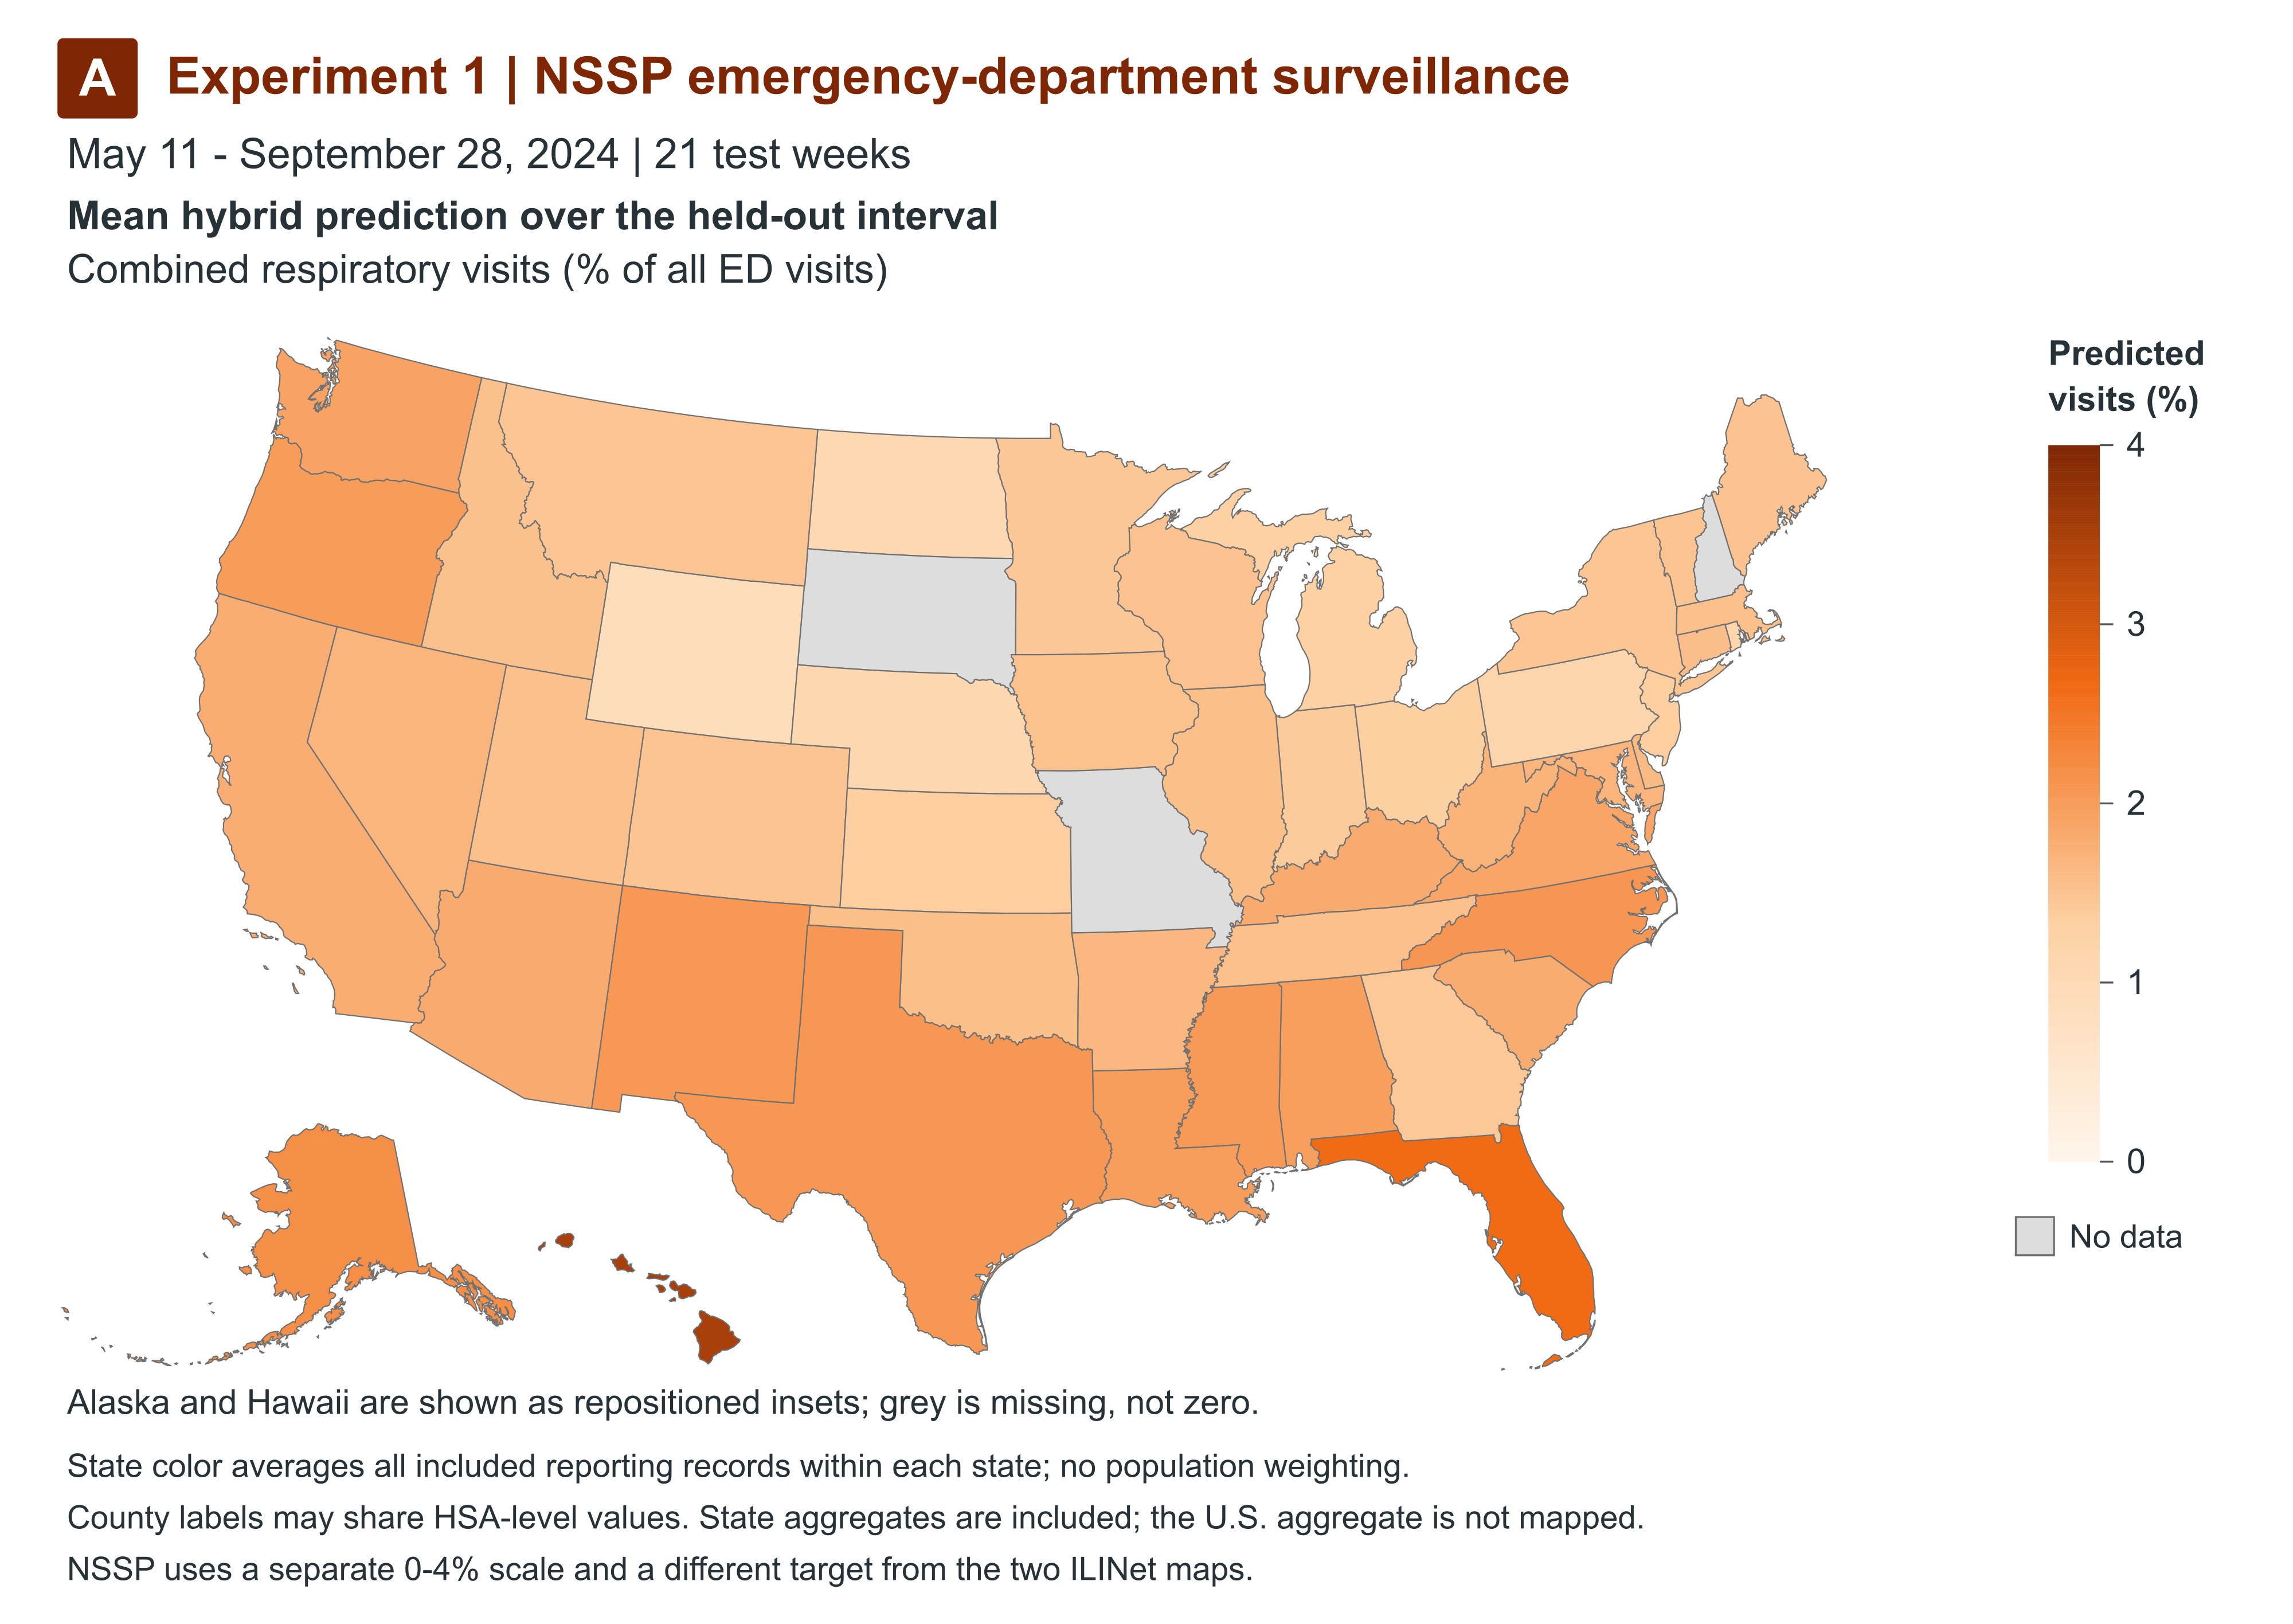

### Contemporary ILINet: mean predicted outpatient ILI percentage

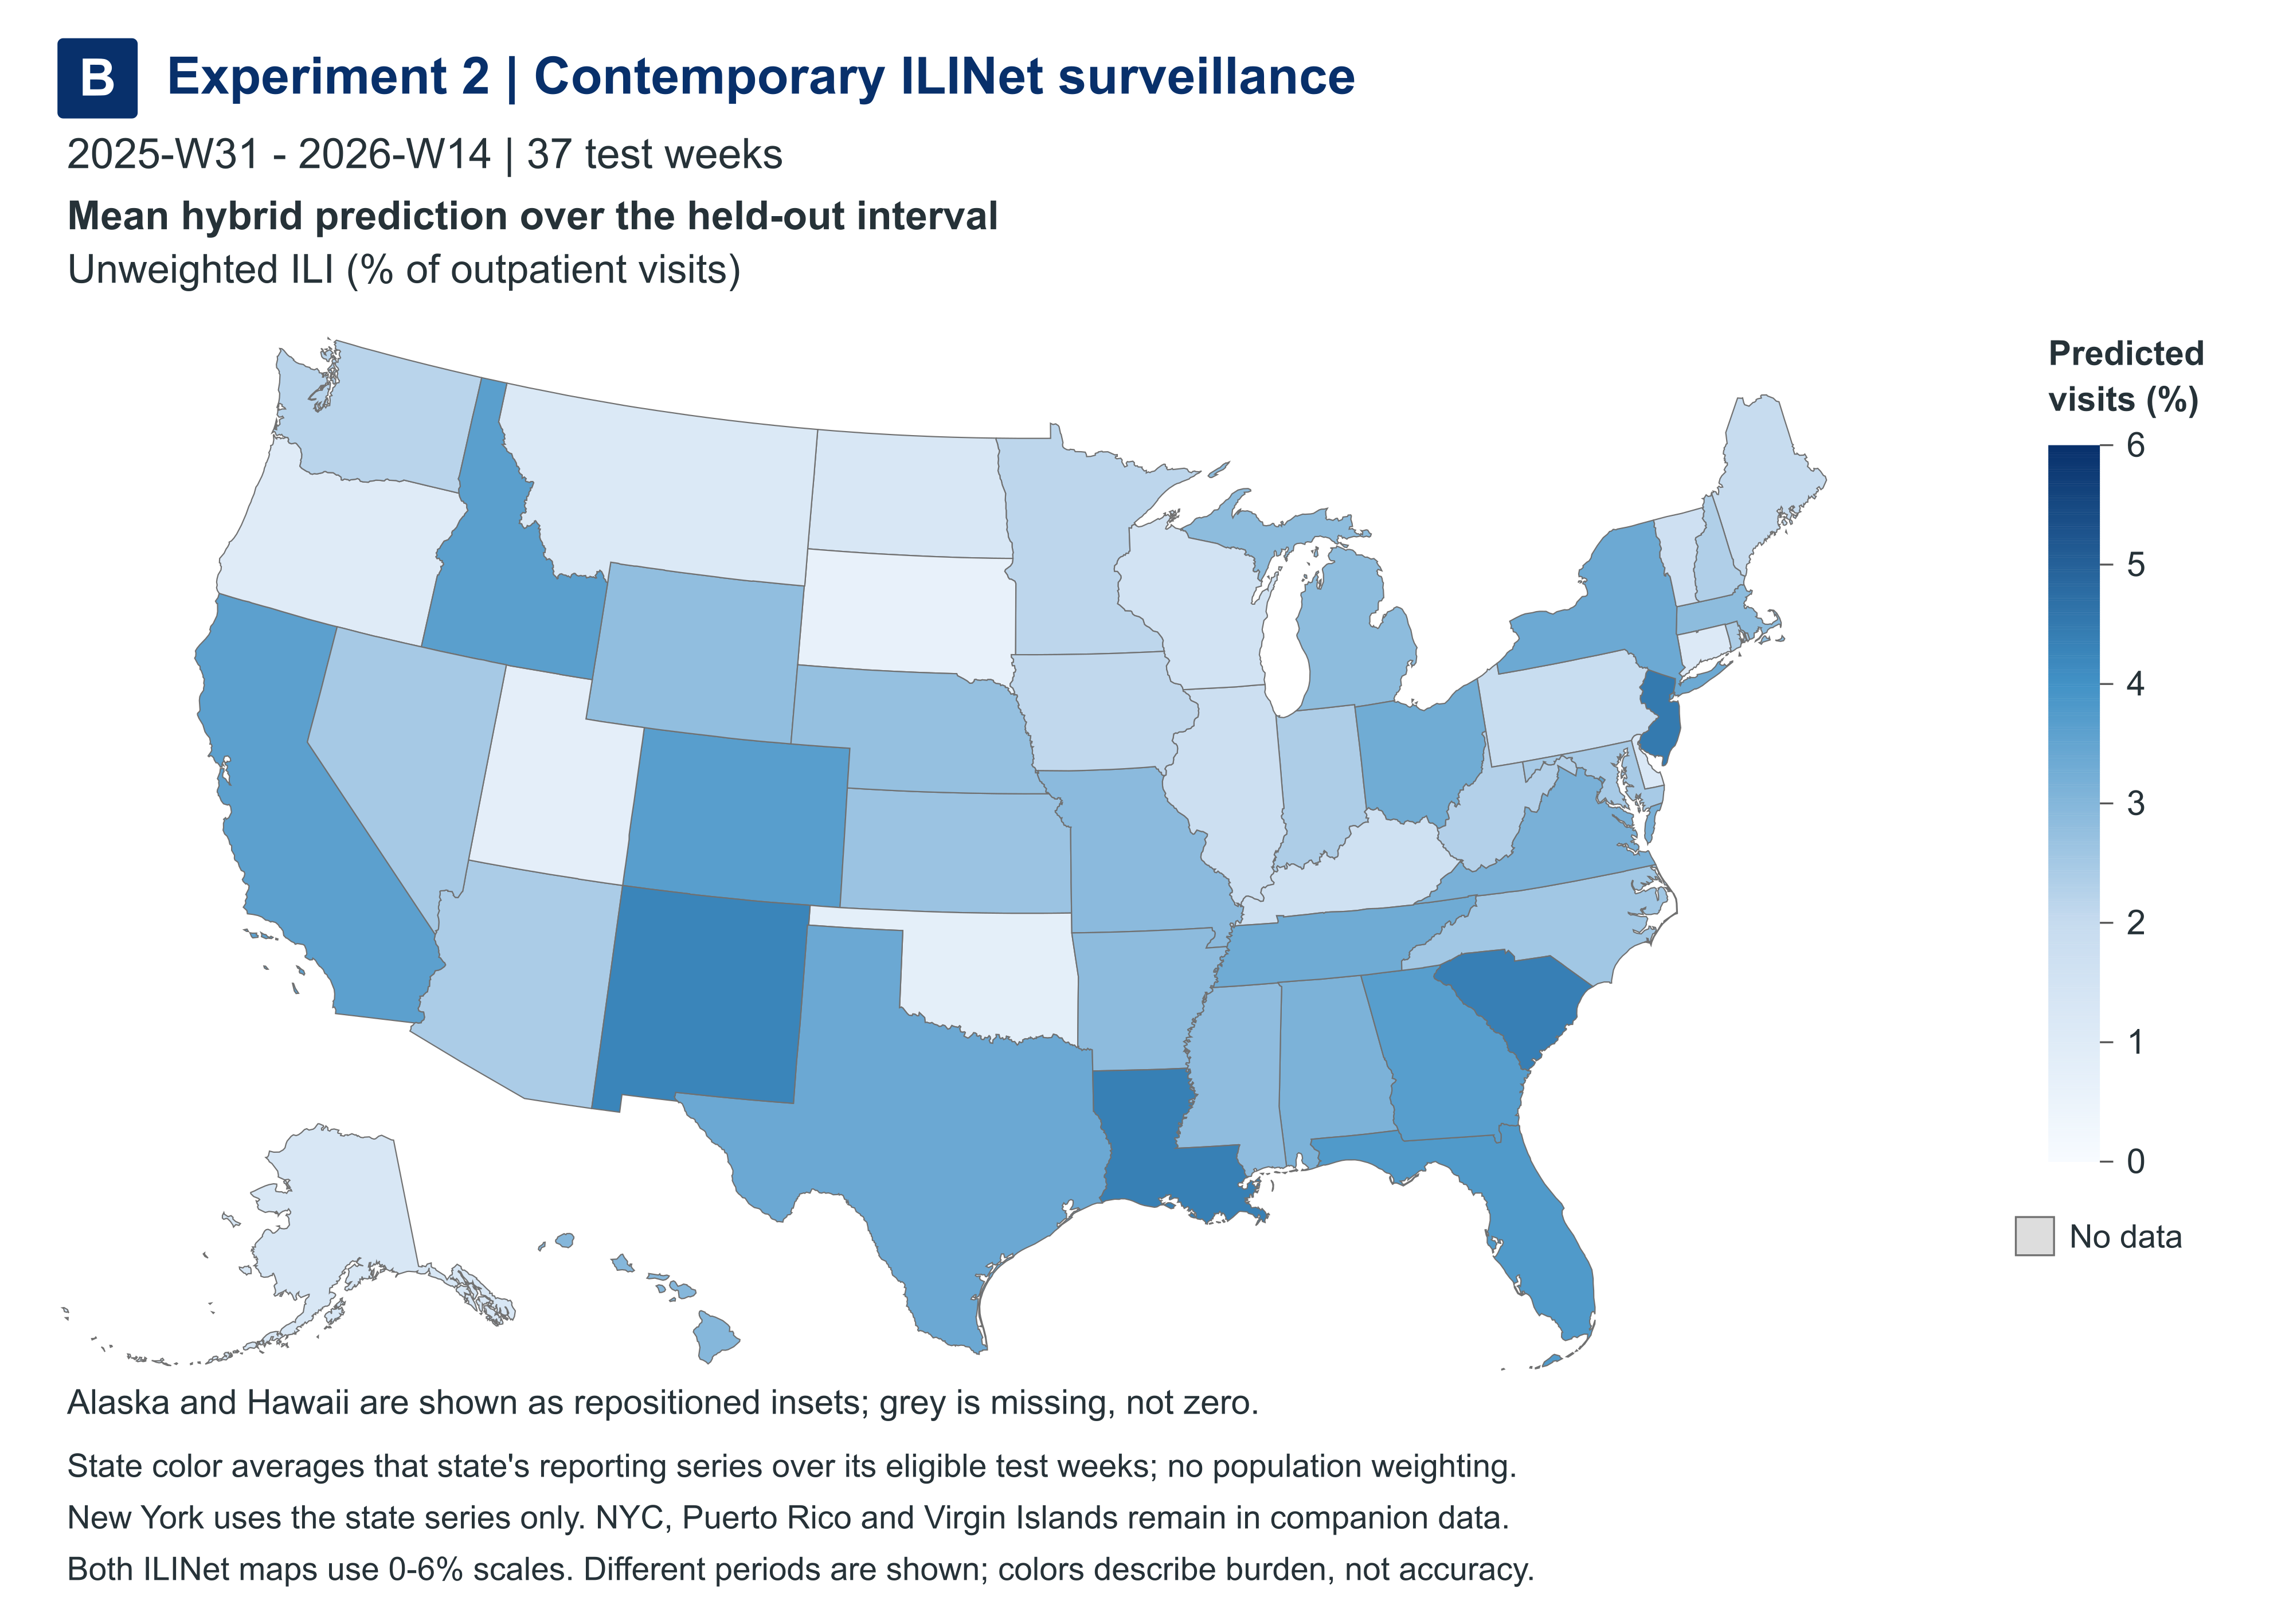

### Historical ILINet: mean predicted outpatient ILI percentage

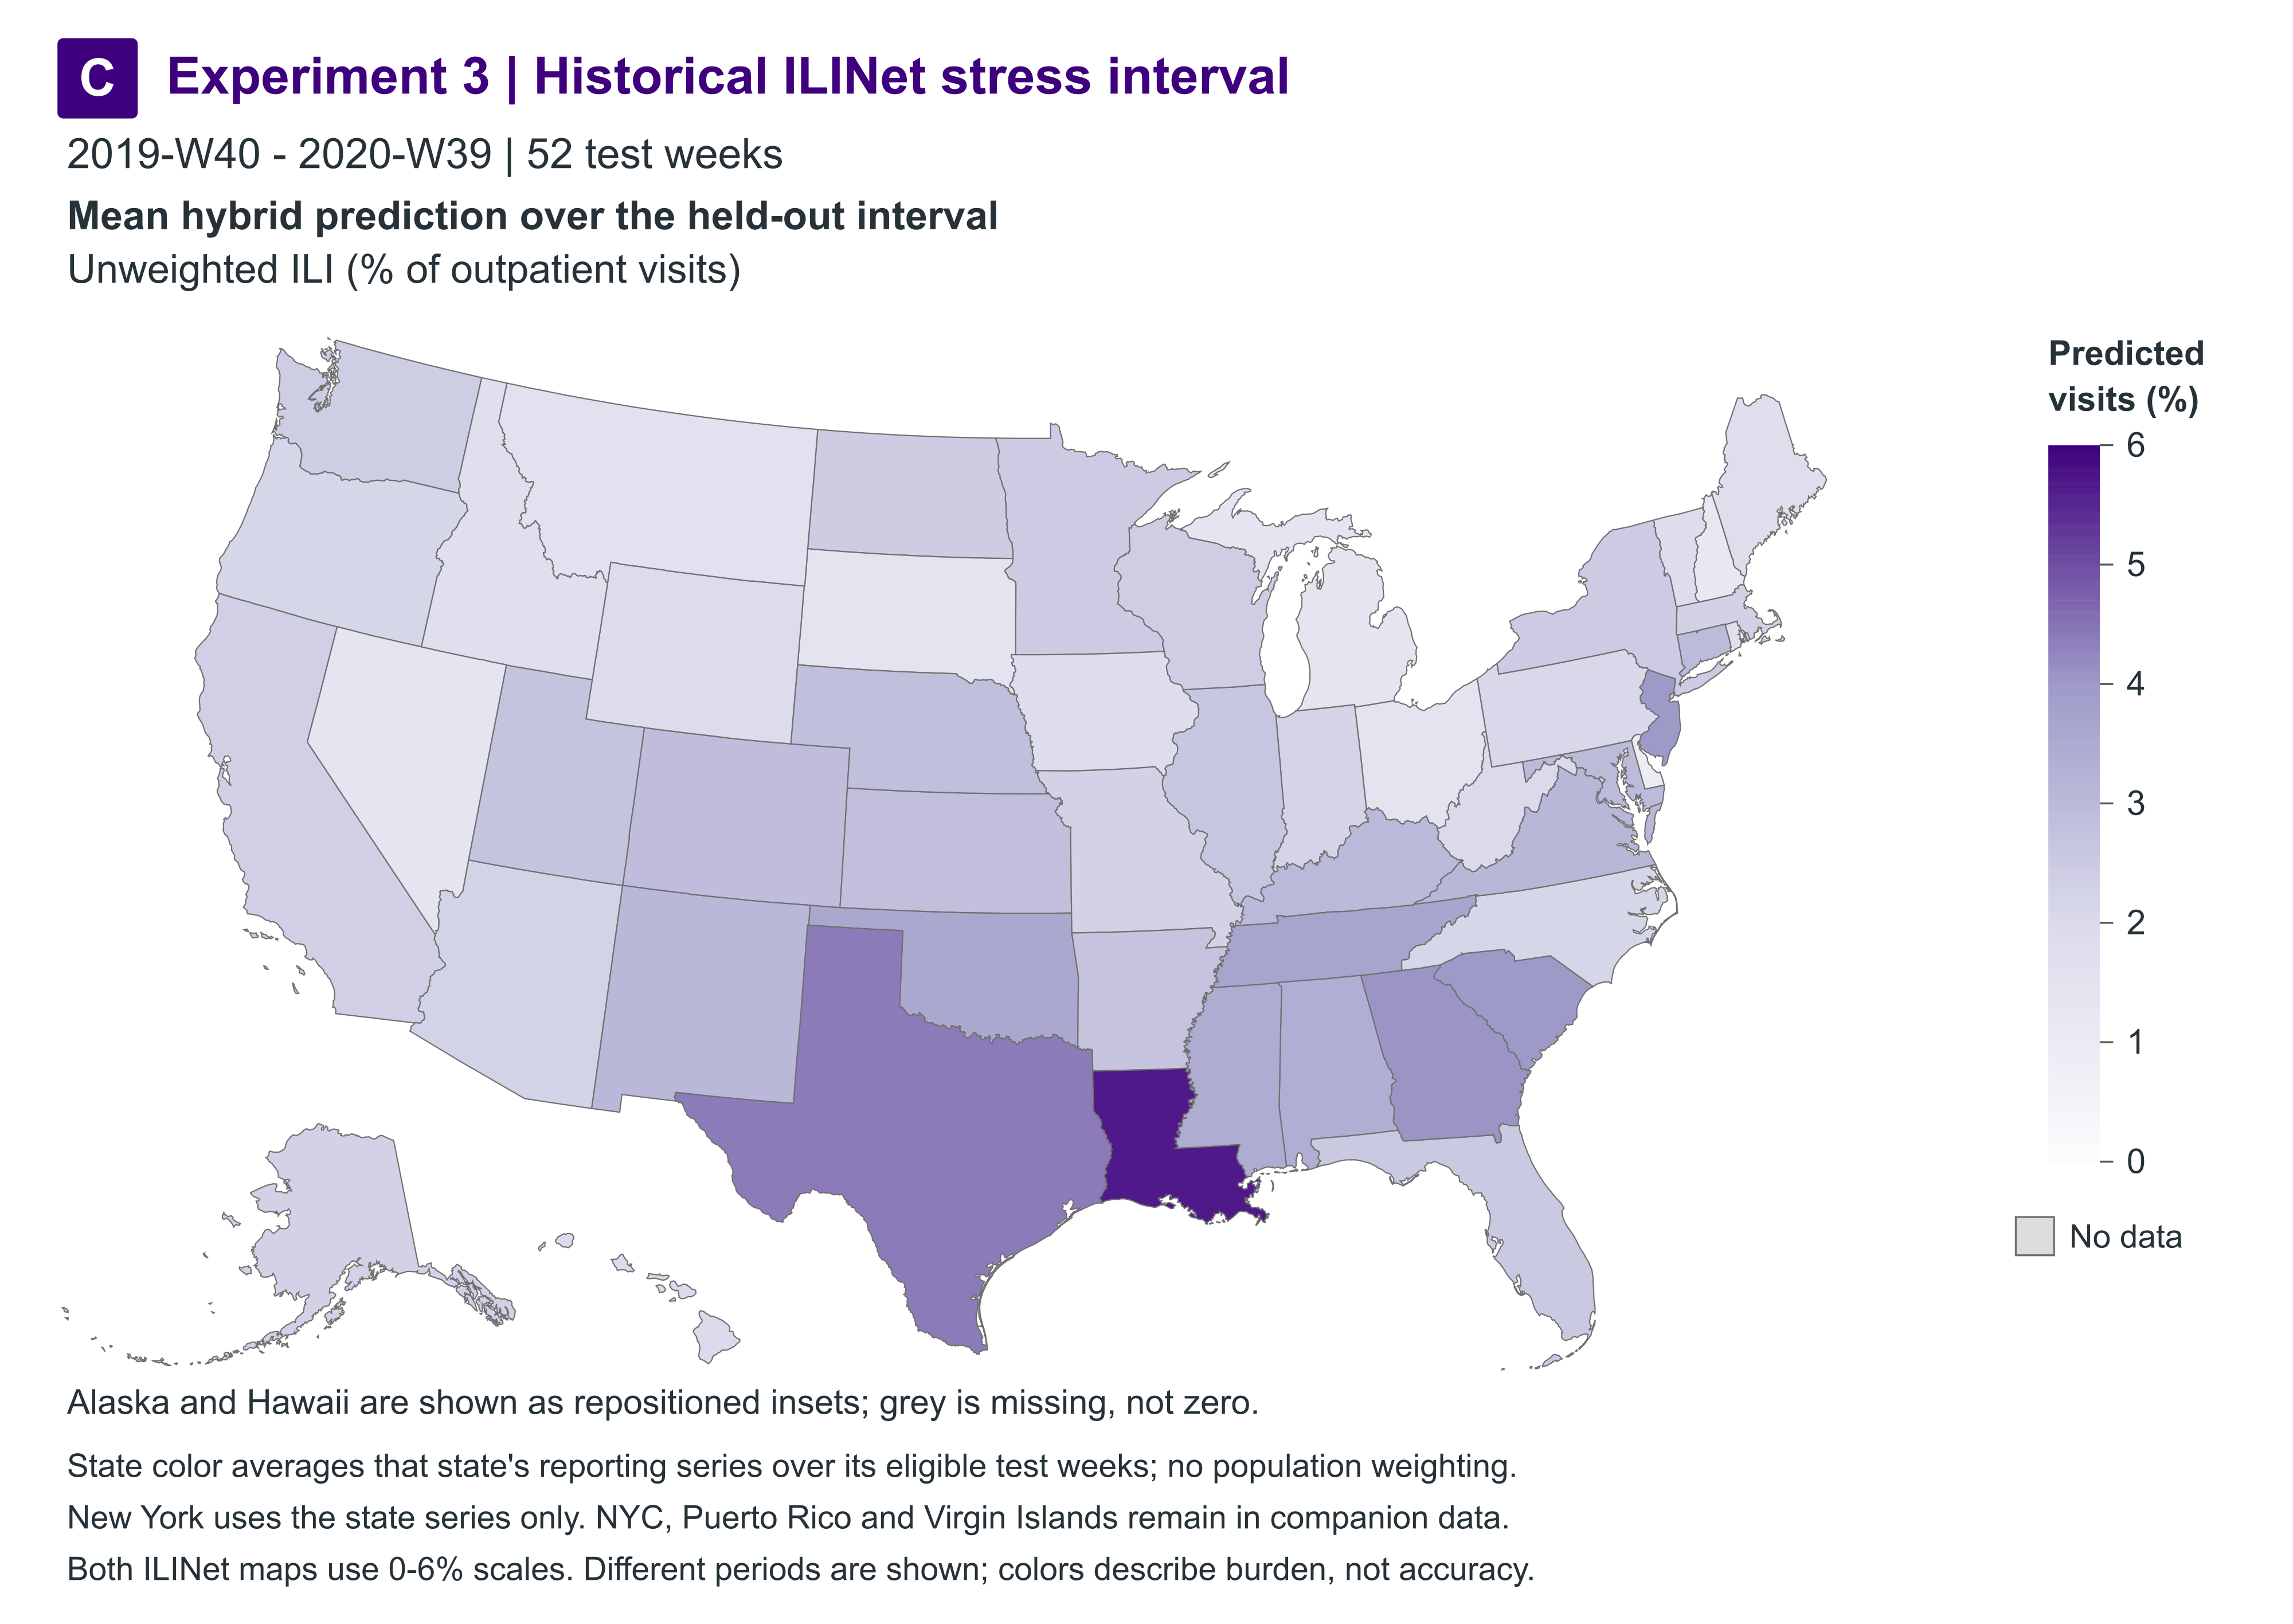

In [8]:
map_rows = rows("manuscript/latex/map_values.csv")
map_checked = 0
for exp, target_name, _, _, _ in EXPERIMENTS:
    region = "geography" if "nssp" in exp else "REGION"
    groups = defaultdict(list)
    for r in all_predictions[exp]:
        groups[r[region]].append(r)
    for saved in [r for r in map_rows if r["Experiment"] == exp]:
        members = groups[saved["Reporting_Unit"]]
        mean_pred = math.fsum(float(r["Hybrid_InvMSE"]) for r in members)/len(members)
        mean_obs = math.fsum(float(r[target_name]) for r in members)/len(members)
        assert len(members) == int(saved["Records"])
        assert len({r["epi_order"] for r in members}) == int(saved["Weeks"])
        assert math.isclose(mean_pred,float(saved["Mean_Prediction"]),rel_tol=1e-12,abs_tol=1e-12)
        assert math.isclose(mean_obs,float(saved["Mean_Observed"]),rel_tol=1e-12,abs_tol=1e-12)
        map_checked += 1
print("PASS: map value/record/week calculations checked:",map_checked)
for caption, figure in [("NSSP: mean predicted respiratory ED percentage", "fig13.png"),
                        ("Contemporary ILINet: mean predicted outpatient ILI percentage", "fig14.png"),
                        ("Historical ILINet: mean predicted outpatient ILI percentage", "fig15.png")]:
    display(Markdown(f"### {caption}"))
    display(Image(filename=str(ROOT/"manuscript/latex/figures"/figure),width=720))

## 6. Classical benchmarks and sensitivity comparisons

### Classical models

ARIMA $(p,d,q)$ combines autoregressive terms, differencing and moving-average **error** terms;
the last are not the three-week averaging baseline. SARIMA adds $(P,D,Q)_{52}$ with a period
of 52 observations. Classical models use each series' target history, not the hybrid's auxiliary
signals or clustering indicators. The retained search has three nonseasonal and three seasonal
candidates, rather than an exhaustive order search.

Orders are selected using pooled chronological validation RMSE, then MAE, and refitted on full
pre-test history. One order is retained per experiment/family, but numerical parameters are fitted
separately to each reporting series. `SARIMAX` (statsmodels) uses L-BFGS fitting and fixed-parameter
filtering with predicted-information-set forecasts. Earlier completed test observations update
the forecasting state; parameters are not refitted to test outcomes. This is rolling one-step
forecasting, not one forecast of the entire test interval made at its start.

Candidates require at least 95% finite prediction coverage. Full NSSP seasonal selection also
requires at least 90% optimizer convergence; the ILINet selectors do not impose that extra gate.
**Coverage is not convergence:** selected final runs have 100% coverage, but NSSP ARIMA/SARIMA
converged for 2,248/2,261 of 2,264 fitted series, and historical ILINet SARIMA for 53 of 54.
Finite predictions from nonconverged fits remain scored. Slower seasonal-differenced candidates
failed the retained screening/retry convergence checks and were not promoted, which does not
establish that seasonal differencing is generally ineffective.

The first table resolves archived final-run candidate IDs through
[`pilot_config.json`](../benchmarks/sarima/pilot_config.json). NSSP uses the full run, not the earlier
60-series pilot. Fitting/selection implementation: [`sarima_pilot.py`](../benchmarks/sarima/sarima_pilot.py),
[`benchmark guide`](../benchmarks/sarima/README.md), and
[`screening evidence`](../archive/classical_screening/README.md).

### Ensemble weighting

Section 3 defines the locked inverse-validation-MSE combination. The alternative gives each
unchanged component forecast one third of the weight:

$$
\hat{y}_{\mathrm{equal}}=\frac{\hat{y}_{\mathrm{RF}}+\hat{y}_{\mathrm{GBR}}+\hat{y}_{\mathrm{MLP}}}{3}
$$

The second table reconstructs both combinations and verifies their archived scores. **NSSP here
uses the 47,534 original records, not the primary 13,356 HSA-weeks.** Equal weighting is slightly
better for NSSP and nearly indistinguishably better for historical ILINet; locked weighting is
slightly better for contemporary ILINet. Equal weighting is competitive, not uniformly superior.
This retrospective comparison does not replace the locked weights, test their stability across
seasons, or establish equal-weight performance on primary HSA-week units.

### Geographic scoring

The third table isolates the original-record, repeated HSA-source and equal-HSA-week populations
described in Section 4. The existing aggregation first joins classical forecasts on identical
geographic/week keys and targets, then averages target and each model's forecasts within HSA-week.
These cells rescore saved pairs; they do not regenerate the aggregation or train HSA-specific models.

Implementation: [`sensitivity_analysis.py::main` and `metrics`](../manuscript/latex/sensitivity_analysis.py).
Full [weighting](../manuscript/latex/sensitivity_data/S2_ensemble_weighting_metrics.csv) and
[geographic](../manuscript/latex/sensitivity_data/S3_nssp_geographic_metrics.csv) tables preserve
historical labels such as `Primary mixed-source records`; display labels identify their current
comparison role. That script's first block **imports** earlier auxiliary-lag summaries, not new
fits. See [development provenance](../archive/development/README.md). These retrospective checks
and the post-review scoring decision do not create untouched confirmatory evidence.

In [9]:
# Read-only Section 6 tables. No fitting, model imports, file writes, or map generation.
# rows(): Setup input helper for CSV/archive evidence and recorded hash checks.
# Candidate definitions: benchmarks/sarima/pilot_config.json (data only, not imported code).
# Original fitting: benchmarks/sarima/sarima_pilot.py::fit_and_predict_group (linked above).
# Original sensitivities: manuscript/latex/sensitivity_analysis.py::main and ::metrics.
# The helper below exposes the score arithmetic using Python's standard library.
def section6_score(observed, predicted):
    assert len(observed) == len(predicted) and len(observed) > 1
    assert all(math.isfinite(v) for v in observed + predicted)
    n = len(observed)
    mean = math.fsum(observed) / n
    errors = [p-y for y,p in zip(observed, predicted)]
    sse = math.fsum(e*e for e in errors)
    sst = math.fsum((y-mean)**2 for y in observed)
    assert sst > 0
    return {"N":n, "MAE":math.fsum(abs(e) for e in errors)/n,
            "RMSE":math.sqrt(sse/n), "R2":1-sse/sst}

def section6_assert_score(calculated, archived):
    for metric in ("N", "MAE", "RMSE", "R2"):
        assert math.isclose(calculated[metric], float(archived[metric]),
                            rel_tol=1e-10, abs_tol=1e-10), (metric, calculated, archived)

# 1. Resolve exact orders from final-run candidate IDs, without reselecting anything.
section6_config = json.loads((ROOT/"benchmarks/sarima/pilot_config.json").read_text(encoding="utf-8"))
section6_candidates = {r["name"]:r for r in section6_config["candidate_models"]}
section6_benchmark_sources = [
    ("NSSP", "nssp_full/test/AR1/summary.csv", "nssp_full/test/SARIMA_100x100_52/summary.csv"),
    ("Contemporary ILINet", "arima_extension_exp2_exp3/exp2/final_test_summary.csv", "exp2/final_test_summary.csv"),
    ("Historical ILINet", "arima_extension_exp2_exp3/exp3/final_test_summary.csv", "exp3/final_test_summary.csv"),
]
section6_benchmark_lines = ["### Selected classical benchmark configurations", "",
                          "| Experiment | ARIMA order | SARIMA order |", "| :--- | :--- | :--- |"]
SECTION6_BENCHMARKS = []
for section6_label, section6_arima_path, section6_sarima_path in section6_benchmark_sources:
    section6_orders = []
    section6_ids = []
    for section6_relative in (section6_arima_path, section6_sarima_path):
        section6_summary_rows = rows("results/reference/classical/" + section6_relative)
        assert len(section6_summary_rows) == 1
        section6_summary = section6_summary_rows[0]
        assert float(section6_summary["Coverage"]) == 1.0
        section6_definition = section6_candidates[section6_summary["Candidate"]]
        section6_ids.append(section6_summary["Candidate"])
        section6_order = "(" + ",".join(map(str, section6_definition["order"])) + ")"
        if section6_definition["seasonal"]:
            section6_seasonal = section6_definition["seasonal_order"]
            section6_order += " × (" + ",".join(map(str, section6_seasonal[:3])) + f") [{section6_seasonal[3]}]"
        section6_orders.append(section6_order)
    SECTION6_BENCHMARKS.append({"Experiment":section6_label, "ARIMA":section6_orders[0],
                                "SARIMA":section6_orders[1], "Candidate_IDs":section6_ids})
    section6_benchmark_lines.append(f"| {section6_label} | {section6_orders[0]} | {section6_orders[1]} |")
section6_benchmark_lines += ["", "[52] denotes the seasonal period. These are archived configurations, not newly fitted models."]
display(Markdown("\n".join(section6_benchmark_lines)))

# 2. Reconstruct existing locked/equal combinations and verify all six archived scores.
section6_models = ("RandomForest", "GradientBoosting", "MLP")
section6_saved_weights = rows("manuscript/latex/sensitivity_data/S2_ensemble_weights.csv")
section6_saved_weight_metrics = rows("manuscript/latex/sensitivity_data/S2_ensemble_weighting_metrics.csv")
section6_weight_lines = ["### Ensemble weights: locked versus equal", "",
    "NSSP here uses the original record-level scoring, not primary HSA-week scoring. RMSE is in percentage points.", "",
    "| Experiment | N | Locked RMSE | Equal RMSE | Locked R² | Equal R² |",
    "| :--- | ---: | ---: | ---: | ---: | ---: |"]
SECTION6_WEIGHT_COMPARISON = []
section6_nssp_records = None
for section6_i, (section6_exp, section6_target, _, _, _) in enumerate(EXPERIMENTS, start=1):
    section6_label = f"Experiment {section6_i}"
    section6_records = rows(f"results/reference/hybrid/{section6_exp}/predictions/{section6_exp}_predictions.csv")
    section6_ws = [r for r in section6_saved_weights if r["Experiment"] == section6_label]
    assert {r["Model"] for r in section6_ws} == set(section6_models)
    section6_inverse = {r["Model"]:1/max(float(r["Validation_MSE"]),1e-12) for r in section6_ws}
    section6_weights = {m:v/math.fsum(section6_inverse.values()) for m,v in section6_inverse.items()}
    for section6_w in section6_ws:
        assert math.isclose(section6_weights[section6_w["Model"]], float(section6_w["Weight"]), rel_tol=1e-12, abs_tol=1e-12)
    for section6_record in section6_records:
        section6_rebuilt = math.fsum(section6_weights[m]*float(section6_record[m]) for m in section6_models)
        assert math.isclose(section6_rebuilt, float(section6_record["Hybrid_InvMSE"]), rel_tol=1e-12, abs_tol=1e-12)
    section6_y = [float(r[section6_target]) for r in section6_records]
    section6_locked = section6_score(section6_y, [float(r["Hybrid_InvMSE"]) for r in section6_records])
    section6_equal = section6_score(section6_y, [math.fsum(float(r[m]) for m in section6_models)/3 for r in section6_records])
    for section6_rule, section6_calculated in [("Inverse validation MSE (primary)",section6_locked),
                                               ("Equal weights (retrospective)",section6_equal)]:
        section6_archived = next(r for r in section6_saved_weight_metrics
                                if r["Experiment"] == section6_label and r["Weighting"] == section6_rule)
        section6_assert_score(section6_calculated, section6_archived)
    section6_name = ("NSSP (record-weighted)", "Contemporary ILINet", "Historical ILINet")[section6_i-1]
    SECTION6_WEIGHT_COMPARISON.append({"Experiment":section6_name, "Locked":section6_locked, "Equal":section6_equal})
    section6_weight_lines.append(
        f"| {section6_name} | {section6_locked['N']:,} | {section6_locked['RMSE']:.6f} | "
        f"{section6_equal['RMSE']:.6f} | {section6_locked['R2']:.6f} | {section6_equal['R2']:.6f} |"
    )
    if section6_i == 1:
        section6_nssp_records = section6_records
section6_weight_lines += ["", "Equal weighting is competitive; this does not replace the locked weights or measure seasonal stability."]
display(Markdown("\n".join(section6_weight_lines)))

# 3. Rescore the existing three hybrid cohorts; never regenerate the HSA-week file.
assert section6_nssp_records is not None
section6_hsa_repeated = [r for r in section6_nssp_records if r["trend_source"] == "HSA"]
section6_hsa_week = rows("manuscript/latex/sensitivity_data/S3_hsa_week_mean_predictions.csv")
assert len(section6_nssp_records) == 47534 and len(section6_hsa_repeated) == 46515
assert len(section6_hsa_week) == 13356
assert len({(r["hsa_nci_id"], r["epi_order"]) for r in section6_hsa_week}) == 13356
section6_geo_saved = rows("manuscript/latex/sensitivity_data/S3_nssp_geographic_metrics.csv")
section6_geo_lines = ["### Geographic scoring: original records to primary HSA-weeks", "",
    "Hybrid forecasts are unchanged. The last row is the current primary NSSP evaluation; RMSE is in percentage points.", "",
    "| Scoring population | N | Hybrid RMSE | Hybrid R² |", "| :--- | ---: | ---: | ---: |"]
SECTION6_GEOGRAPHIC_COMPARISON = []
for section6_archive_label, section6_display_label, section6_cohort in [
    ("Primary mixed-source records", "Comparison: original mixed-source records", section6_nssp_records),
    ("HSA-source county-key records", "Comparison: repeated HSA-source records", section6_hsa_repeated),
    ("Equal HSA-week means", "Primary: one observation per HSA-week", section6_hsa_week),
]:
    section6_calculated = section6_score([float(r["percent_visits_combined"]) for r in section6_cohort],
                                         [float(r["Hybrid_InvMSE"]) for r in section6_cohort])
    section6_archived = next(r for r in section6_geo_saved
                            if r["Scoring_basis"] == section6_archive_label and r["Model"] == "Hybrid_InvMSE")
    section6_assert_score(section6_calculated, section6_archived)
    SECTION6_GEOGRAPHIC_COMPARISON.append({"Scoring_basis":section6_display_label, **section6_calculated})
    section6_geo_lines.append(
        f"| {section6_display_label} | {section6_calculated['N']:,} | {section6_calculated['RMSE']:.6f} | {section6_calculated['R2']:.6f} |"
    )
section6_geo_lines += ["", "All nine displayed hybrid score rows (six weighting rows plus three geographic rows) match the archived metrics. "
    "No model was fitted, no new scoring configuration was introduced, and no source result or map was changed."]
display(Markdown("\n".join(section6_geo_lines)))


# Display the already verified primary scores together; no new predictions or scoring rule.
benchmark_comparison = []
for i, (experiment, _, _, _, _) in enumerate(EXPERIMENTS):
    label = ("NSSP: HSA-week", "Contemporary ILINet: reporting units", "Historical ILINet: reporting units")[i]
    for method in ("Hybrid_InvMSE", "ARIMA", "SARIMA"):
        if i == 0:
            verified = next(r for r in HSA_PRIMARY if r["Model"] == method)
        elif method == "Hybrid_InvMSE":
            verified = next(r for r in REVIEW_SUMMARY if r["Experiment"] == experiment)
        else:
            verified = next(r for r in CLASSICAL_RECORD_COMPARISON
                            if r["Experiment"] == experiment and r["Model"] == method)
        benchmark_comparison.append([label, method] + [verified[k] for k in ("N", "MAE", "RMSE", "R2")])
show_table("Hybrid and classical benchmarks: current primary scoring",
           ["Experiment / scored unit", "Model", "N", "MAE (pp)", "RMSE (pp)", "R²"], benchmark_comparison)

### Selected classical benchmark configurations

| Experiment | ARIMA order | SARIMA order |
| :--- | :--- | :--- |
| NSSP | (1,0,0) | (1,0,0) × (1,0,0) [52] |
| Contemporary ILINet | (0,1,1) | (1,0,1) × (1,0,0) [52] |
| Historical ILINet | (1,1,0) | (2,0,0) × (1,0,0) [52] |

[52] denotes the seasonal period. These are archived configurations, not newly fitted models.

### Ensemble weights: locked versus equal

NSSP here uses the original record-level scoring, not primary HSA-week scoring. RMSE is in percentage points.

| Experiment | N | Locked RMSE | Equal RMSE | Locked R² | Equal R² |
| :--- | ---: | ---: | ---: | ---: | ---: |
| NSSP (record-weighted) | 47,534 | 0.803473 | 0.801147 | 0.671288 | 0.673189 |
| Contemporary ILINet | 1,774 | 0.716087 | 0.716932 | 0.890186 | 0.889926 |
| Historical ILINet | 2,808 | 0.833458 | 0.833380 | 0.894556 | 0.894576 |

Equal weighting is competitive; this does not replace the locked weights or measure seasonal stability.

### Geographic scoring: original records to primary HSA-weeks

Hybrid forecasts are unchanged. The last row is the current primary NSSP evaluation; RMSE is in percentage points.

| Scoring population | N | Hybrid RMSE | Hybrid R² |
| :--- | ---: | ---: | ---: |
| Comparison: original mixed-source records | 47,534 | 0.803473 | 0.671288 |
| Comparison: repeated HSA-source records | 46,515 | 0.810114 | 0.669304 |
| Primary: one observation per HSA-week | 13,356 | 0.972459 | 0.598622 |

All nine displayed hybrid score rows (six weighting rows plus three geographic rows) match the archived metrics. No model was fitted, no new scoring configuration was introduced, and no source result or map was changed.

### Hybrid and classical benchmarks: current primary scoring

| Experiment / scored unit | Model | N | MAE (pp) | RMSE (pp) | R² |
| --- | --- | --- | --- | --- | --- |
| NSSP: HSA-week | Hybrid_InvMSE | 13,356 | 0.618219 | 0.972459 | 0.598622 |
| NSSP: HSA-week | ARIMA | 13,356 | 0.733037 | 1.123077 | 0.464660 |
| NSSP: HSA-week | SARIMA | 13,356 | 0.830732 | 1.288207 | 0.295661 |
| Contemporary ILINet: reporting units | Hybrid_InvMSE | 1,774 | 0.399268 | 0.716087 | 0.890186 |
| Contemporary ILINet: reporting units | ARIMA | 1,774 | 0.469467 | 0.837639 | 0.849741 |
| Contemporary ILINet: reporting units | SARIMA | 1,774 | 0.423609 | 0.739467 | 0.882898 |
| Historical ILINet: reporting units | Hybrid_InvMSE | 2,808 | 0.465868 | 0.833458 | 0.894556 |
| Historical ILINet: reporting units | ARIMA | 2,808 | 0.504042 | 0.899203 | 0.877265 |
| Historical ILINet: reporting units | SARIMA | 2,808 | 0.490138 | 0.851388 | 0.889971 |

## 7. Optional execution controls — leave off for review

All four switches below are `False`. They are ordinary Python variables guarding these blocks,
not filesystem locks. No switch needs to be enabled to inspect or recalculate Sections 1–6.

| Switch | If enabled | Effect |
|---|---|---|
| `RUN_PRIMARY` | Verifies exact raw snapshots, then runs all three hybrid experiments, regardless of `EXPERIMENT_INDEX` | Retrains models; writes predictions, metrics and legacy diagnostic plots under `results/<experiment_name>/`; repeat runs can overwrite earlier rerun outputs |
| `RUN_SENSITIVITY` | Stages reference CSVs and runs `sensitivity_analysis.py` | No learner training; writes supplementary exports under `results/reproduced/sensitivity/`, potentially replacing earlier rerun exports |
| `RUN_EXISTING_TESTS` | Runs `unittest` discovery in `tests/` | The current seven tests do not train models or write scientific results; future tests may differ and imports may create caches |
| `EXTRACT_REFERENCE` | Hash-checks and stages archived CSVs under `results/reference/` | Writes missing files; refuses different existing content; no training |

The primary runner uses original record-key training, not deduplicated HSA training, and does not
launch the separate ARIMA/SARIMA search or manuscript heat-map renderer. Sensitivity execution
also triggers extraction even when `EXTRACT_REFERENCE` is `False`. Extraction is not transactional:
some missing files may already have been added before a later conflict stops it.

The current saved-metric unit test checks the original NSSP record-weighted result, not the
HSA-primary result. Passing the tests does not verify every paper claim or substitute for raw-file
hash checks. Exact snapshots and full scientific dependencies are prerequisites for intentional
refitting; consult the [repository instructions](../README.md) and
[benchmark guide](../benchmarks/sarima/README.md) first.

### Safe editing

1. Save personal notes as a separate notebook. Editing Markdown or comments does not alter
   archived scientific evidence. Save with `Ctrl+S` to retain notebook text and displayed outputs.
2. Keep all four switches off and run review cells in order. Changed calculation code can produce
   different displays: label exploratory edits and do not disable integrity assertions to hide a failure.
3. Do not overwrite reference archives, predictions, map values or images. Use a **complete separate
   project copy** for intentional future experiments; copying only the notebook does not redirect
   script-derived output paths. Reference outputs are not technically immutable against arbitrary edits.

`run_script` uses the current kernel's `sys.executable` to launch a named script, waits for it, and
raises on failure. Defining the helper alone does not execute a script. Switches do not guard
manually launched commands or newly added code. Turning one off does not undo writes or stop an
already running child process. The final status below checks **all four** switches; saved output
still reflects its recorded execution, not a guarantee about a later kernel session.

In [10]:
RUN_PRIMARY = False
RUN_SENSITIVITY = False
RUN_EXISTING_TESTS = False
EXTRACT_REFERENCE = False  # Set True only to stage CSVs for original CLI scripts; no fitting.

# Subprocess is a standard-library process launcher, not a hidden calculation.
# Each command names the source file doing the work and uses this notebook's interpreter.
import subprocess
def run_script(relative, *arguments):
    subprocess.run([sys.executable, str(ROOT/relative), *map(str,arguments)], cwd=ROOT, check=True)

if RUN_PRIMARY:
    run_script("scripts/verify_data.py")
    run_script("scripts/run_pipeline.py", "--profile", "primary")
if EXTRACT_REFERENCE or RUN_SENSITIVITY:
    # Original scripts require CSVs on disk. Extraction is deliberate and hash-checked.
    with zipfile.ZipFile(ARCHIVE) as z:
        for item in manifest["files"]:
            path = ROOT/item["path"]
            assert path.resolve().is_relative_to((ROOT/"results/reference").resolve())
            raw = z.read(item["path"])
            assert hashlib.sha256(raw).hexdigest() == item["sha256"]
            if path.exists():
                assert path.read_bytes() == raw, "Refusing to overwrite different reference evidence"
            else:
                path.parent.mkdir(parents=True,exist_ok=True)
                path.write_bytes(raw)
    print("Matching reference CSVs staged; no different evidence overwritten.")
if RUN_SENSITIVITY:
    run_script("manuscript/latex/sensitivity_analysis.py", "--repo", ROOT,
               "--source-dir", ROOT/"manuscript/latex/sensitivity_data/source",
               "--output-dir", ROOT/"results/reproduced/sensitivity")
if RUN_EXISTING_TESTS:
    subprocess.run([sys.executable,"-m","unittest","discover","-s","tests"],cwd=ROOT,check=True)
if not any((RUN_PRIMARY, RUN_SENSITIVITY, RUN_EXISTING_TESTS, EXTRACT_REFERENCE)):
    print("All four switches are off. No training, scientific tests, reference extraction, or supplementary exports executed.")

All four switches are off. No training, scientific tests, reference extraction, or supplementary exports executed.
